In [1]:
import json
import time
import importlib
import genetic_algorithm
from pathlib import Path

# Mereload perubahan module
importlib.reload(genetic_algorithm) # https://www.geeksforgeeks.org/python/importlib-package-in-python/

from genetic_algorithm import encode_state, decode_state, genetic_algorithm, fitness
from visual import plotState
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Membaca file packages.json
# https://www.geeksforgeeks.org/python/read-json-file-using-python/
with open("../data/packages.json") as file:
    packages = json.load(file)

# Membaca file truck.json
with open("../data/truck.json") as file:
    truck = json.load(file)

In [3]:
def saveRun(initial_chromosome_random, best_chromosome, packages, truck, folder, duration):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    
    initial_state_random = decode_state(initial_chromosome_random, packages)
    out = {"inside": initial_state_random, "outside": [id for id in packages if id not in initial_state_random], "value": fitness(initial_chromosome_random, packages, truck)}
    with open(folder / "initialState.json", "w") as f:
        json.dump(out, f, indent=2)
    plotState(initial_state_random, packages, truck, folder / "initialState.png")

    final_state = decode_state(best_chromosome, packages)
    out = {"inside": final_state, "outside": [id for id in packages if id not in final_state], "value": fitness(best_chromosome, packages, truck), "duration": duration}
    with open(folder / "finalState.json", "w") as f:
        json.dump(out, f, indent=2)
    plotState(final_state, packages, truck, folder / "finalState.png")

    return fitness(best_chromosome, packages, truck)

pop 30, iter 25, run 0: final 1710, duration 6.135 s


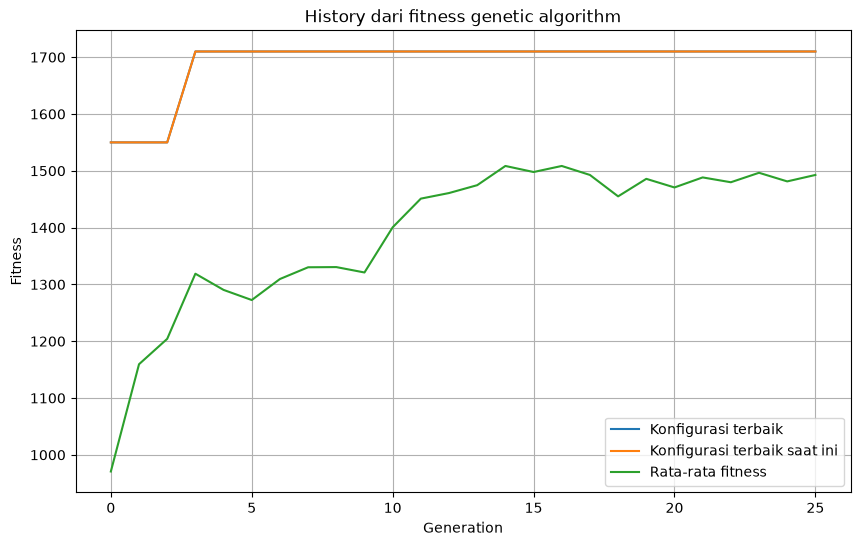

pop 30, iter 25, run 1: final 1795, duration 4.618 s


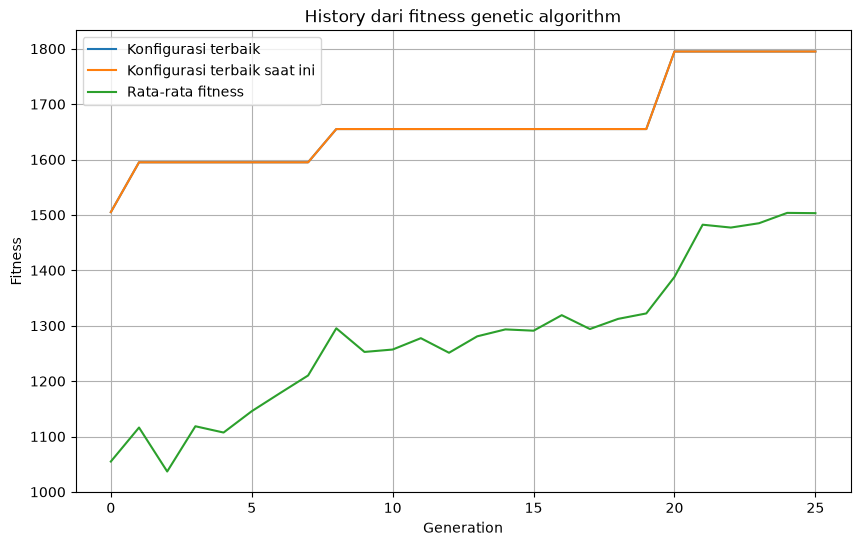

pop 30, iter 25, run 2: final 1915, duration 5.245 s


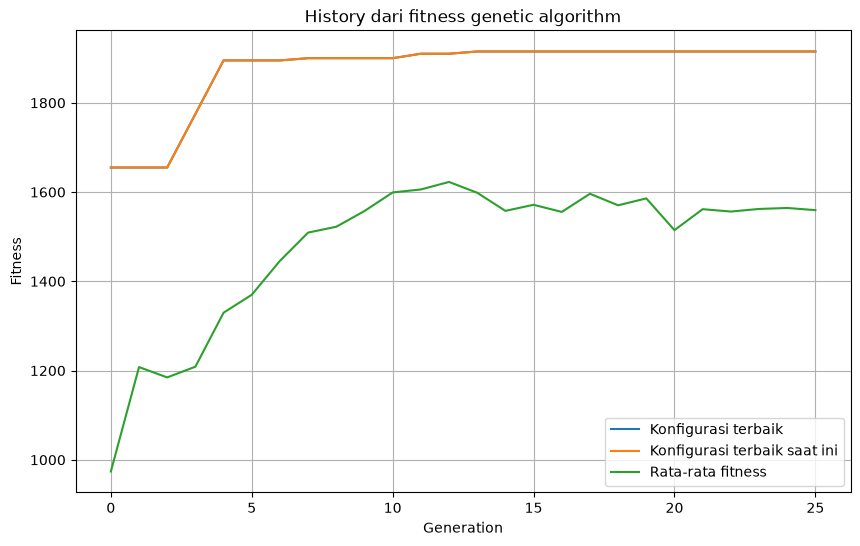

pop 30, iter 50, run 0: final 1995, duration 10.297 s


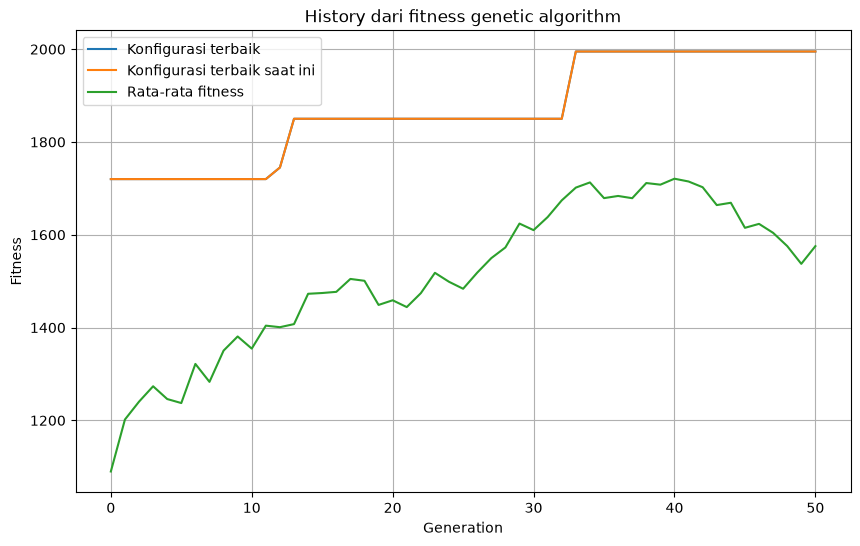

pop 30, iter 50, run 1: final 1950, duration 13.820 s


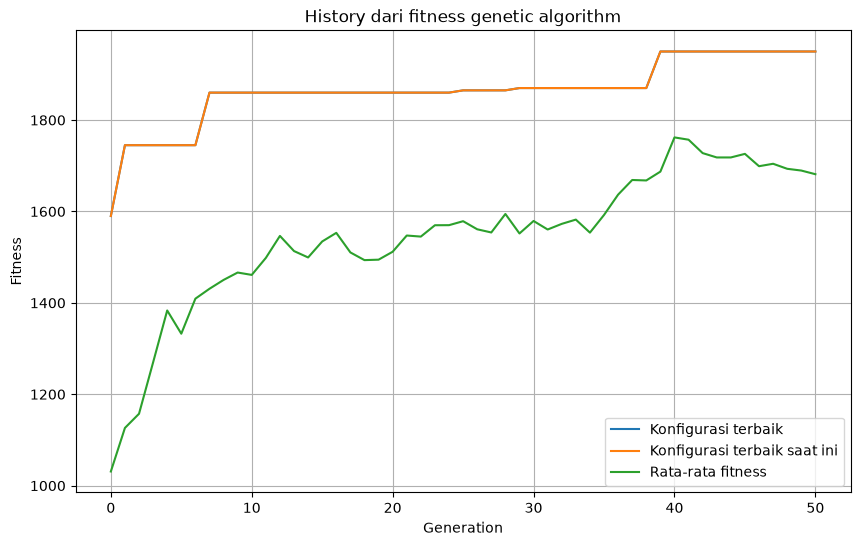

pop 30, iter 50, run 2: final 1915, duration 10.066 s


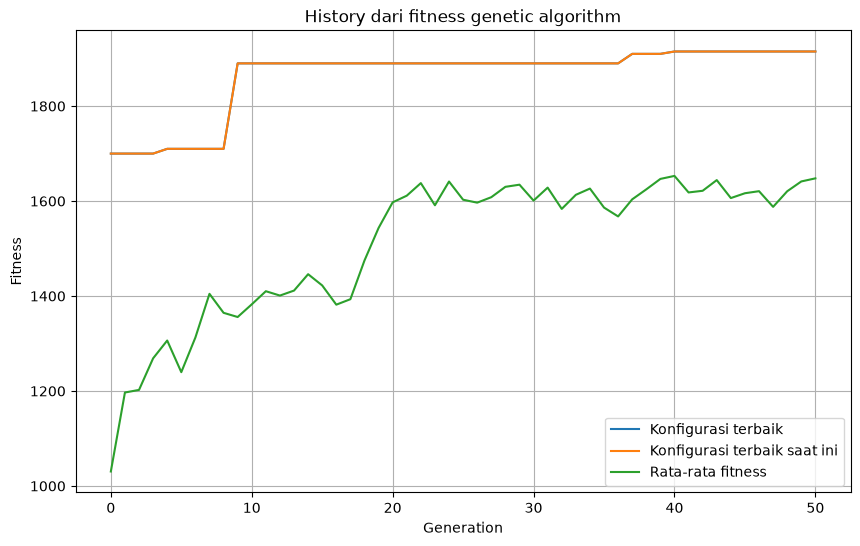

pop 30, iter 100, run 0: final 2005, duration 30.554 s


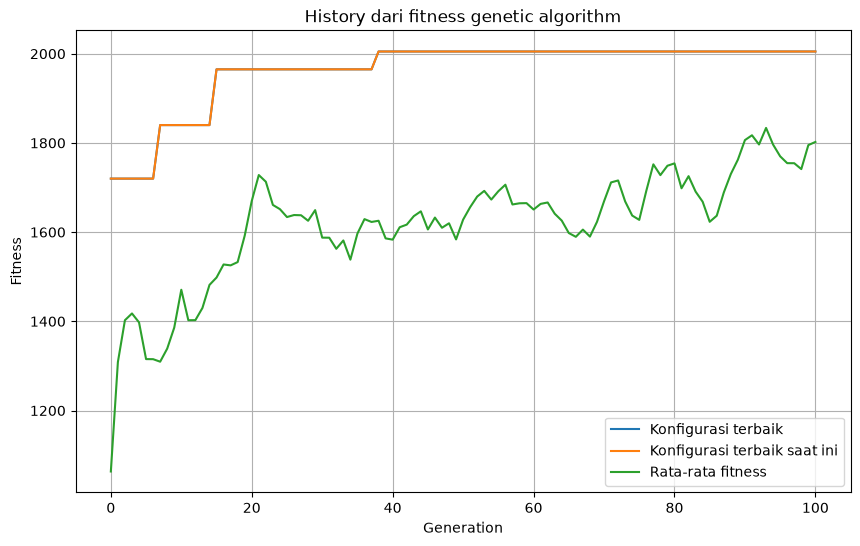

pop 30, iter 100, run 1: final 1730, duration 21.346 s


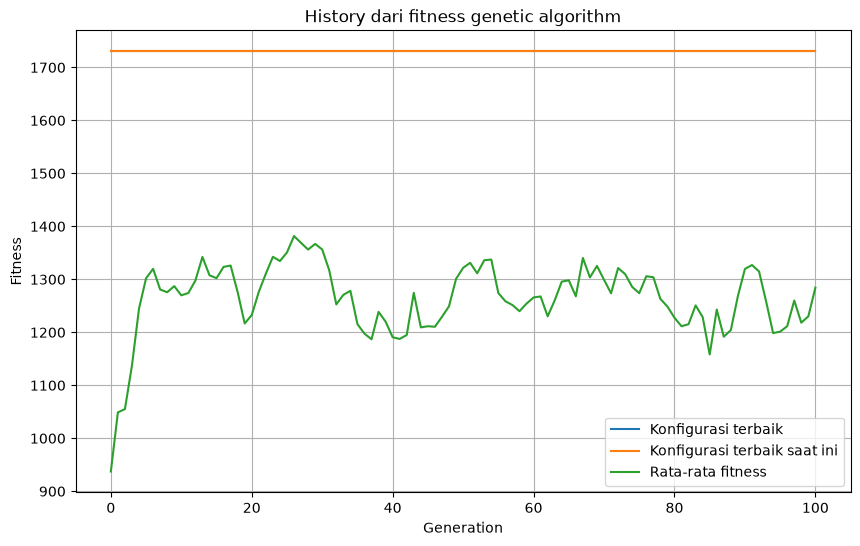

pop 30, iter 100, run 2: final 1990, duration 24.114 s


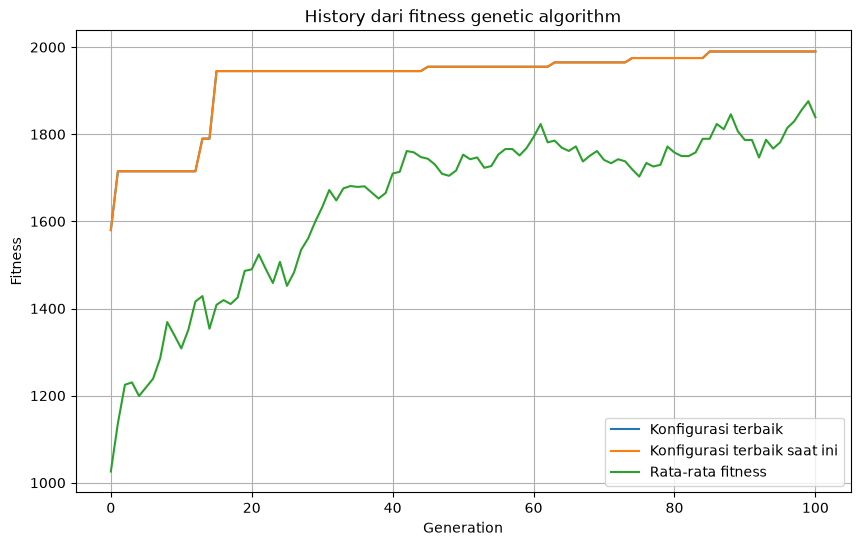

pop 10, iter 50, run 0: final 1655, duration 1.230 s


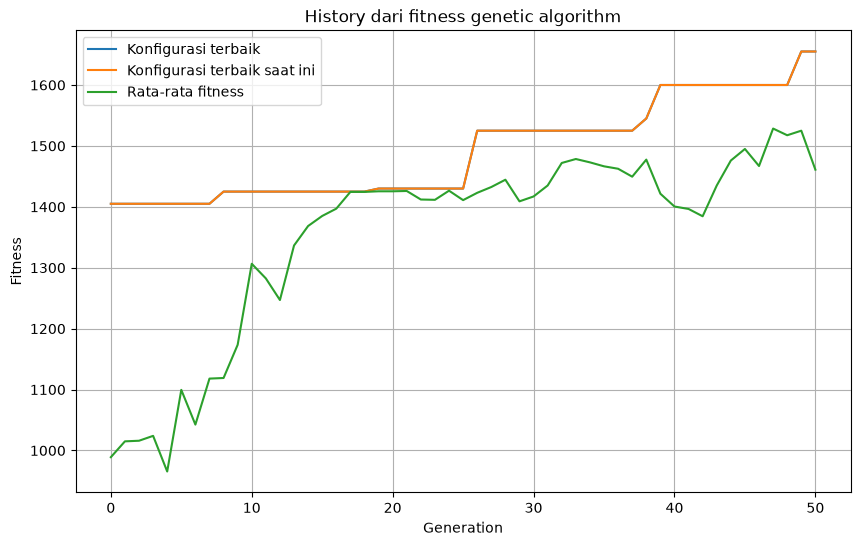

pop 10, iter 50, run 1: final 1755, duration 1.656 s


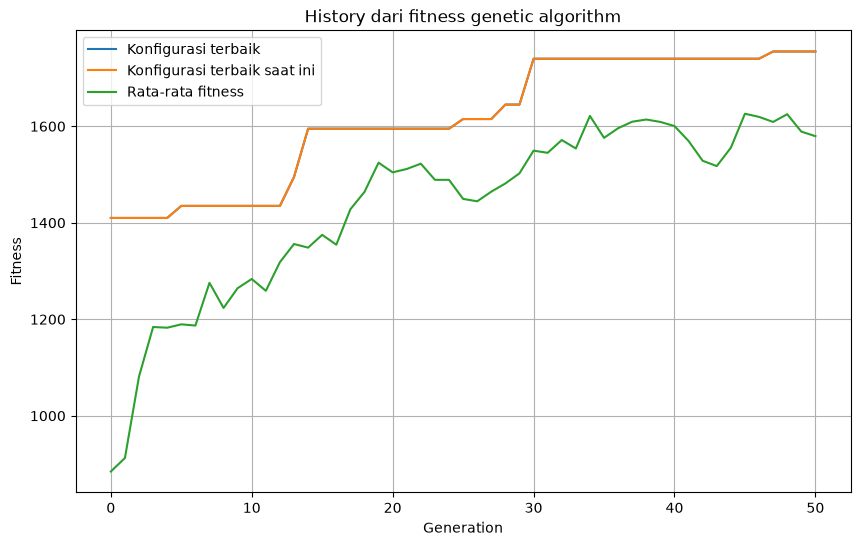

pop 10, iter 50, run 2: final 1610, duration 1.443 s


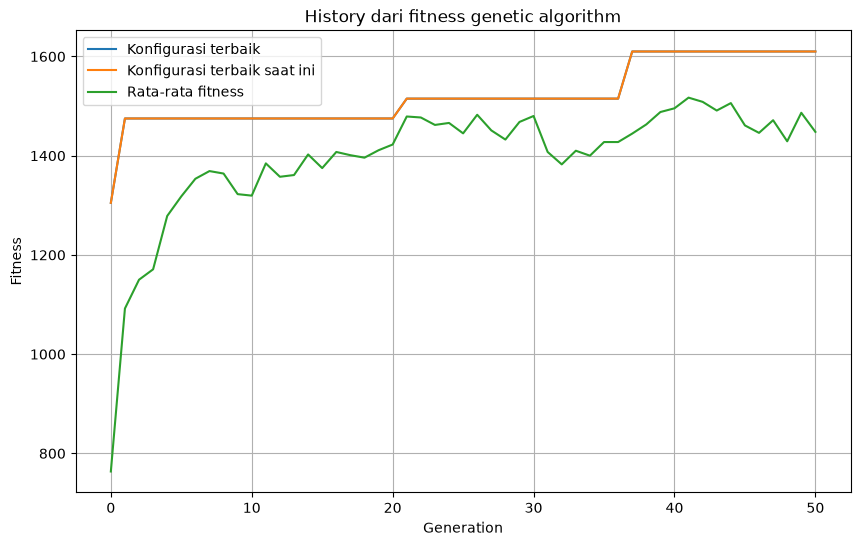

pop 50, iter 50, run 0: final 1935, duration 21.929 s


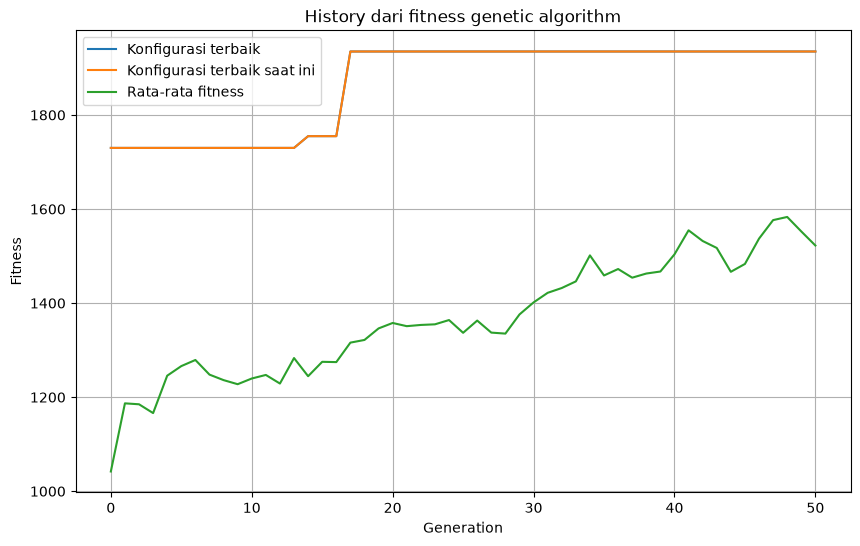

pop 50, iter 50, run 1: final 1910, duration 21.985 s


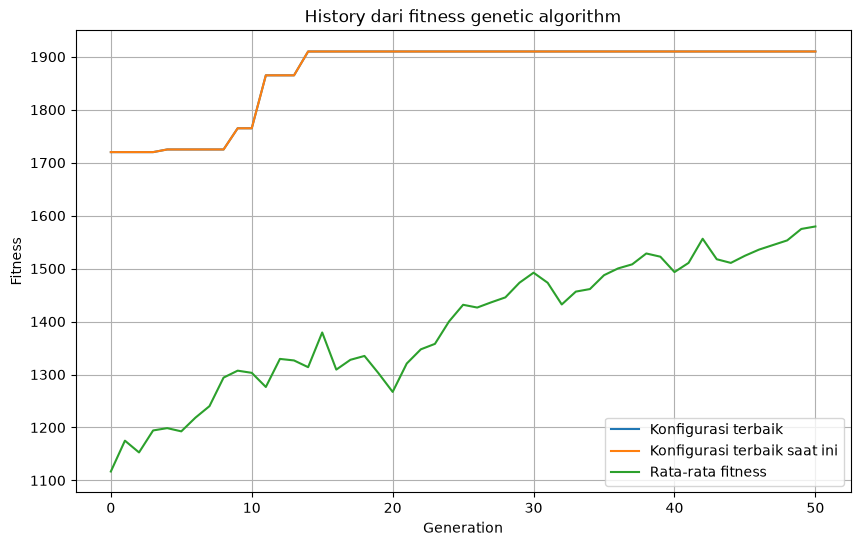

pop 50, iter 50, run 2: final 2045, duration 30.476 s


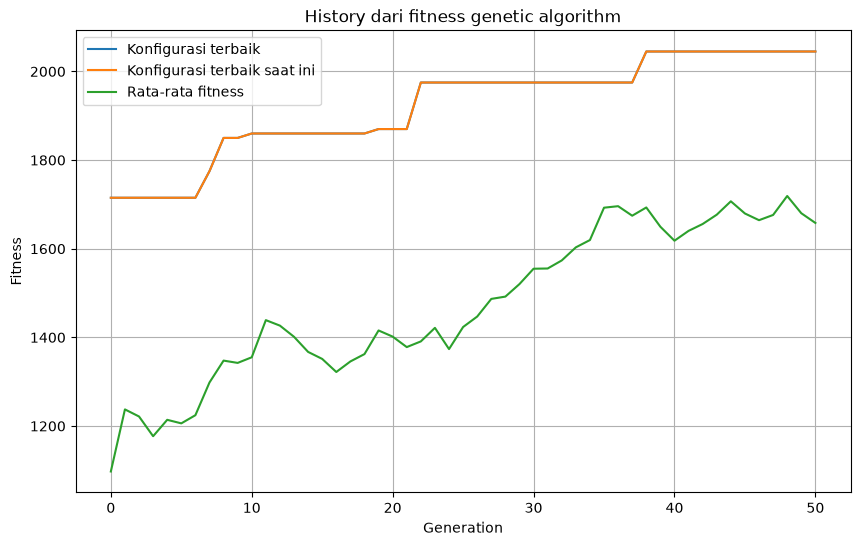

In [4]:
for pop_size, max_iter, x in [(p, i, x) for p, i in [(30, 25), (30, 50), (30, 100), (10, 50), (50, 50)] for x in range(3)]:
    start = time.perf_counter()
    initial_chromosome_random, best_chromosome, history_best, history_curr_best, history_avg = genetic_algorithm(
        packages,
        truck,
        pop_size=pop_size,
        max_iter=max_iter,
        mutation_rate=0.1
    )
    duration = time.perf_counter() - start
    folder = f"../../output/genetic_algorithm/pop{pop_size}_iter{max_iter}/run{x}"
    fitness_value = saveRun(initial_chromosome_random, best_chromosome, packages, truck, folder, duration)
    print(f"pop {pop_size}, iter {max_iter}, run {x}: final {fitness_value}, duration {duration:.3f} s")

    generations = range(len(history_best)) # Ukuran dari History panjang 

    plt.figure(figsize=(10, 6))

    plt.plot(generations, history_best, label="Konfigurasi terbaik") # Plot konfigurasi terbaik
    plt.plot(generations, history_curr_best, label="Konfigurasi terbaik saat ini") # Plot konfigurasi terbaik saat ini
    plt.plot(generations, history_avg, label="Rata-rata fitness") # Plot rata-rata fitness

    plt.xlabel("Generation")
    plt.ylabel("Fitness")
    plt.title("History dari fitness genetic algorithm")

    plt.legend()
    plt.grid(True)
    plt.savefig(f"{folder}/plotObj.png", dpi=100)
    plt.show()